# Syntetos–Boylan Approximation (SBA) — From Scratch
### Companion to the Croston guided tutorial

**Learning objective:** understand why SBA exists, calculate its forecast by hand, and implement it in Python without changing the Croston demand-size or interval updates.

We use monthly demand, a common smoothing factor $\alpha=0.2$, initial size equal to the first non-zero demand, and initial interval of one month for the January-start examples. All forecasts are average units per month, not predictions of individual order dates. Run the cells in order.

## 1. Start with the same demand history
January: 10, February: 0, March: 0, April: 12, May: 0, June: 8. Demand occurs three times in six months. The actual gaps are 3 months (Jan → Apr) and 2 months (Apr → Jun).

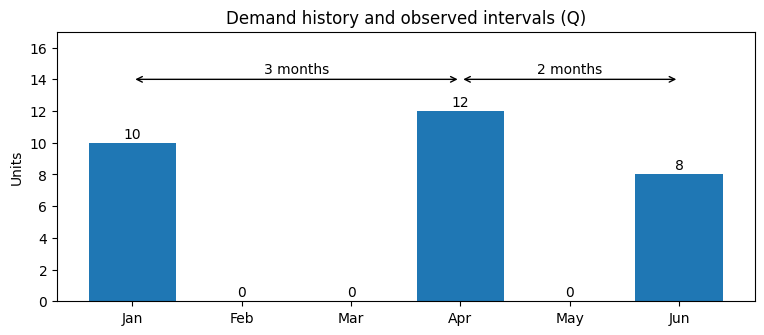

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
months = ['Jan','Feb','Mar','Apr','May','Jun']
demand = np.array([10,0,0,12,0,8])
alpha = 0.2
fig, ax = plt.subplots(figsize=(9,3.5))
ax.bar(months,demand)
for i,v in enumerate(demand): ax.text(i,v+.3,str(v),ha='center')
for a,b,y in [(0,3,14),(3,5,14)]:
    ax.annotate('',(b,y),(a,y),arrowprops={'arrowstyle':'<->'})
    ax.text((a+b)/2,y+.35,f'{b-a} months',ha='center')
ax.set(ylim=(0,17),ylabel='Units',title='Demand history and observed intervals (Q)'); plt.show()

## 2. Recap: ADI and CV²
$$ADI=6/3=2$$
Using the positive quantities 10, 12, 8, the mean is 10 and sample standard deviation is 2.
$$CV^2=(2/10)^2=0.04$$
ADI ≥ 1.32 and CV² < 0.49: **intermittent demand**. This is a useful screening rule, not proof that SBA is best.

In [2]:
positive = demand[demand>0]
print('ADI:',len(demand)/len(positive))
print('CV²:',(positive.std(ddof=1)/positive.mean())**2)

ADI: 2.0
CV²: 0.04000000000000001


## 3. Recap: Z, Q, P and Croston F
| Symbol | Meaning | Units |
|---|---|---|
| Z | Smoothed size of non-zero demand | Units per occurrence |
| Q | Observed gap since the last positive demand | Months |
| P | Smoothed demand interval | Months |
| F | Forecast rate after observing current demand | Units/month |

January initializes Z=10 and P=1. February and March carry both estimates forward. In April, actual demand is 12 and Q=3:
$$Z_{Apr}=0.8(10)+0.2(12)=10.4$$
$$P_{Apr}=0.8(1)+0.2(3)=1.4$$
May has zero demand; both estimates stay unchanged. June has demand 8 and Q=2:
$$Z_{Jun}=0.8(10.4)+0.2(8)=9.92$$
$$P_{Jun}=0.8(1.4)+0.2(2)=1.52$$
$$F_{Jun}^{Croston}=9.92/1.52=6.5263158$$
This forecast is for July, not June. SBA retains these exact Z and P calculations.

## 4. Why SBA? Understand the bias before correcting it
Imagine Z is fixed at 12 and P is equally likely to be 2 or 4 months.

| Scenario | Z | P | Z/P |
|---|---:|---:|---:|
| A | 12 | 2 | 6 |
| B | 12 | 4 | 3 |

Ratio of averages = 12/3 = 4. Average of ratios = (6+3)/2 = 4.5.

$$E[Z/P]\ne E[Z]/E[P]$$
The reciprocal of a positive interval is a convex function. With fixed Z (or under appropriate independence assumptions), variation in P produces upward inversion bias. This toy example illustrates the mechanism; it is not a derivation of the SBA correction or evidence of a 12.5% bias for every SKU. SBA is an approximate statistical correction under specific demand assumptions.

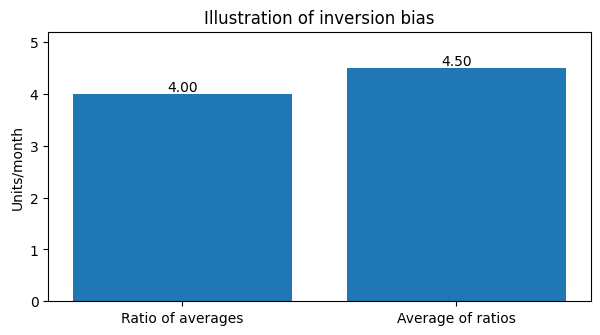

In [3]:
fig,ax=plt.subplots(figsize=(7,3.5))
bars=ax.bar(['Ratio of averages','Average of ratios'],[4,4.5]); ax.bar_label(bars,fmt='%.2f'); ax.set(ylim=(0,5.2),ylabel='Units/month',title='Illustration of inversion bias'); plt.show()

## 5. SBA — guided manual calculation
$$F_t^{SBA}=\left(1-\frac{\alpha}{2}\right)\frac{Z_t}{P_t}$$
**Step 1:** take the smoothing factor 0.2.

**Step 2:** calculate the correction: $1-0.2/2=0.9$. Retain 90% of Croston (reduce by 10%).

**Step 3:** use June's Croston forecast: $9.92/1.52=6.5263158$.

**Step 4:** multiply: $0.9\times6.5263158=5.8736842$.

**Answer: July SBA forecast = 5.87 units/month.** Keep full precision until displaying results. No new smoothing of Z or P is necessary.

Correction: 0.90; Croston: 6.5263; SBA: 5.8737


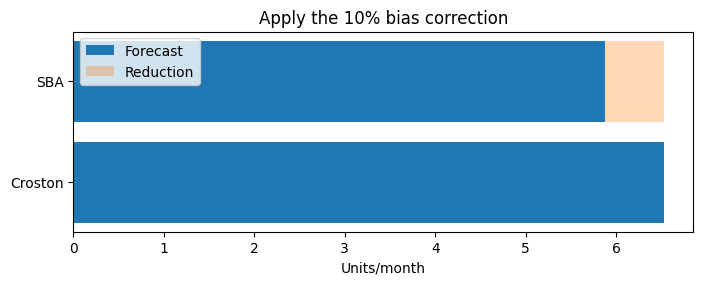

In [4]:
factor = 1-alpha/2
croston_june=9.92/1.52
sba_june=factor*croston_june
print(f'Correction: {factor:.2f}; Croston: {croston_june:.4f}; SBA: {sba_june:.4f}')
fig,ax=plt.subplots(figsize=(8,2.6))
ax.barh(['Croston','SBA'],[croston_june,sba_june],label='Forecast')
ax.barh(['SBA'],[croston_june-sba_june],left=[sba_june],alpha=.3,label='Reduction')
ax.set(xlabel='Units/month',title='Apply the 10% bias correction'); ax.legend(); plt.show()

## 6. Complete month-by-month hand solution
The forecast columns are **after** observing that month's actual demand.

| Month | Actual | Q | Z | P | Croston | SBA |
|---|---:|---:|---:|---:|---:|---:|
| Jan | 10 | — | 10 | 1 | 10 | 9 |
| Feb | 0 | — | 10 | 1 | 10 | 9 |
| Mar | 0 | — | 10 | 1 | 10 | 9 |
| Apr | 12 | 3 | 10.4 | 1.4 | 7.43 | 6.69 |
| May | 0 | — | 10.4 | 1.4 | 7.43 | 6.69 |
| Jun | 8 | 2 | 9.92 | 1.52 | 6.53 | 5.87 |

Notice: zero demand does not update Z or P, so both forecasts stay flat.

## 7. Reusable Python implementation
The function updates both estimates only for positive demand. Leading zero periods have no initialized forecast; the first positive period uses its one-based position as the default initial interval. An explicit positive initial interval may be supplied. The `*_next` columns forecast the next period; `*_for_period` columns are shifted one row so they can be compared fairly with actuals.

In [5]:
def croston_sba(values, alpha=0.2, initial_interval=None):
    values=np.asarray(values,dtype=float)
    if values.ndim!=1 or not len(values) or not np.isfinite(values).all() or (values<0).any():
        raise ValueError('Provide a nonempty series of finite nonnegative demand.')
    if not 0<alpha<=1: raise ValueError('alpha must be in (0,1].')
    if initial_interval is not None and (not np.isfinite(initial_interval) or initial_interval<1):
        raise ValueError('Initial interval must be finite and at least one.')
    z=p=np.nan; last=None; rows=[]
    for i,d in enumerate(values):
        q=np.nan
        elapsed=i-last if last is not None else np.nan
        if d>0:
            if last is None:
                z=d; p=float(i+1 if initial_interval is None else initial_interval)
            else:
                q=i-last
                z=alpha*d+(1-alpha)*z
                p=alpha*q+(1-alpha)*p
            last=i
        f=z/p
        rows.append((d,elapsed,q,z,p,f,(1-alpha/2)*f))
    df=pd.DataFrame(rows,columns=['Actual','Elapsed','Q','Z','P','Croston_next','SBA_next'])
    for method in ['Croston','SBA']:
        df[method+'_for_period']=df[method+'_next'].shift(1)
    return df
result=croston_sba(demand,alpha)
result.index=months
display(result.round(4))
assert np.allclose(result.Z,[10,10,10,10.4,10.4,9.92])
assert np.allclose(result.P,[1,1,1,1.4,1.4,1.52])
assert np.isclose(result.SBA_next.iloc[-1],sba_june)
print('Manual calculation checks passed.')

,Actual,Elapsed,Q,Z,P,Croston_next,SBA_next,Croston_for_period,SBA_for_period
Jan,10.0,NaN,NaN,10.00,1.00,10.0000,9.0000,NaN,NaN
Feb,0.0,1.0,NaN,10.00,1.00,10.0000,9.0000,10.0000,9.0000
Mar,0.0,2.0,NaN,10.00,1.00,10.0000,9.0000,10.0000,9.0000
Apr,12.0,3.0,3.0,10.40,1.40,7.4286,6.6857,10.0000,9.0000
May,0.0,1.0,NaN,10.40,1.40,7.4286,6.6857,7.4286,6.6857
Jun,8.0,2.0,2.0,9.92,1.52,6.5263,5.8737,7.4286,6.6857


Manual calculation checks passed.


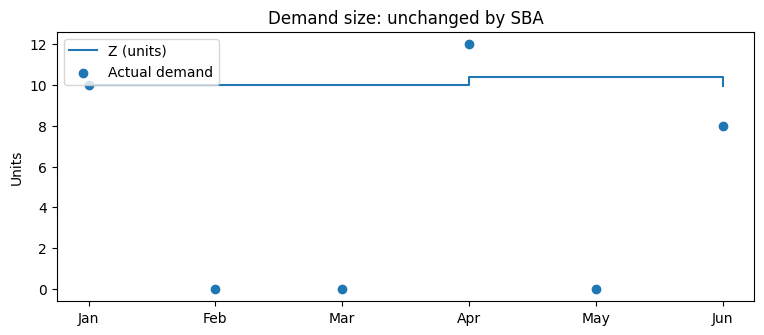

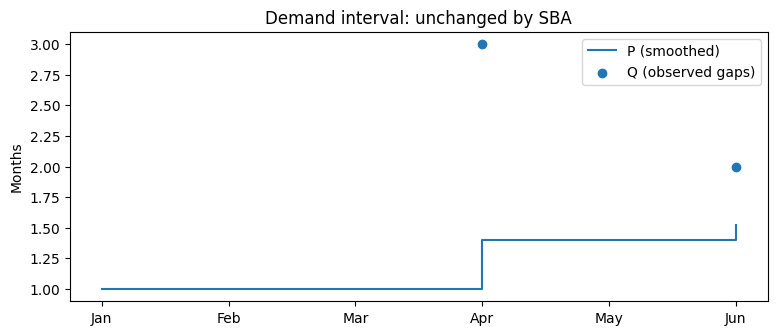

In [6]:
fig,ax=plt.subplots(figsize=(9,3.5))
ax.step(months,result.Z,where='post',label='Z (units)'); ax.scatter(months,demand,label='Actual demand'); ax.set(title='Demand size: unchanged by SBA',ylabel='Units'); ax.legend(); plt.show()
fig,ax=plt.subplots(figsize=(9,3.5))
ax.step(months,result.P,where='post',label='P (smoothed)'); ax.scatter(months,result.Q,label='Q (observed gaps)'); ax.set(title='Demand interval: unchanged by SBA',ylabel='Months'); ax.legend(); plt.show()

## 8. Forecast timeline and future demand
The July forecast is computed using June's actual demand. With no new observations, both methods give a flat future forecast. This is an expected rate, not a prediction that demand occurs every month.

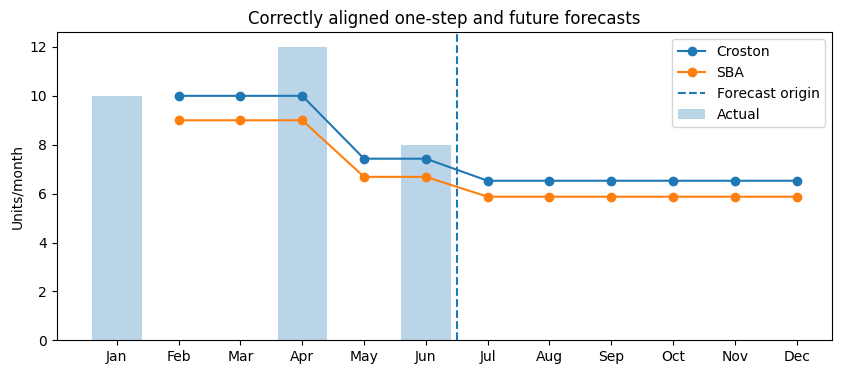

,Croston,SBA
1 month,6.53,5.87
3 months,19.58,17.62
6 months,39.16,35.24


In [7]:
future=['Jul','Aug','Sep','Oct','Nov','Dec']
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(months,demand,alpha=.3,label='Actual')
for method in ['Croston','SBA']:
    vals=list(result[method+'_for_period'])+[result[method+'_next'].iloc[-1]]*6
    ax.plot(months+future,vals,marker='o',label=method)
ax.axvline(5.5,linestyle='--',label='Forecast origin'); ax.set(ylabel='Units/month',title='Correctly aligned one-step and future forecasts'); ax.legend(); plt.show()
display(pd.DataFrame({'Croston':[croston_june*h for h in [1,3,6]],'SBA':[sba_june*h for h in [1,3,6]]},index=['1 month','3 months','6 months']).round(2))

## 9. Second solved example — full year
Extend the same history with July 0, August 0, September 15, October 0, November 10, December 0.

September: Q=3, $Z=0.8(9.92)+0.2(15)=10.936$, $P=0.8(1.52)+0.2(3)=1.816$.

November: Q=2, $Z=0.8(10.936)+0.2(10)=10.7488$, $P=0.8(1.816)+0.2(2)=1.8528$.

December carries forward the November values. Next January's forecast is $10.7488/1.8528$ for Croston and $0.9(10.7488/1.8528)$ for SBA.

,Actual,Elapsed,Q,Z,P,Croston_next,SBA_next,Croston_for_period,SBA_for_period
Jan,10.0,NaN,NaN,10.0000,1.0000,10.0000,9.0000,NaN,NaN
Feb,0.0,1.0,NaN,10.0000,1.0000,10.0000,9.0000,10.0000,9.0000
Mar,0.0,2.0,NaN,10.0000,1.0000,10.0000,9.0000,10.0000,9.0000
Apr,12.0,3.0,3.0,10.4000,1.4000,7.4286,6.6857,10.0000,9.0000
May,0.0,1.0,NaN,10.4000,1.4000,7.4286,6.6857,7.4286,6.6857
Jun,8.0,2.0,2.0,9.9200,1.5200,6.5263,5.8737,7.4286,6.6857
Jul,0.0,1.0,NaN,9.9200,1.5200,6.5263,5.8737,6.5263,5.8737
Aug,0.0,2.0,NaN,9.9200,1.5200,6.5263,5.8737,6.5263,5.8737
Sep,15.0,3.0,3.0,10.9360,1.8160,6.0220,5.4198,6.5263,5.8737
Oct,0.0,1.0,NaN,10.9360,1.8160,6.0220,5.4198,6.0220,5.4198


ADI: 2.4 CV²: 0.05785123966942149
Next January Croston: 5.801381692573402 SBA: 5.221243523316062


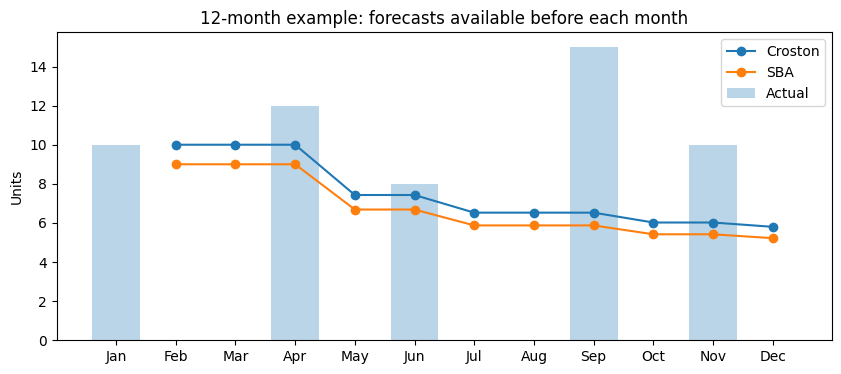

In [8]:
year=np.r_[demand,[0,0,15,0,10,0]]
yr=croston_sba(year,alpha); yr.index=months+future
display(yr.round(4))
assert np.isclose(yr.Z.iloc[-1],10.7488) and np.isclose(yr.P.iloc[-1],1.8528)
print('ADI:',len(year)/sum(year>0),'CV²:',(year[year>0].std(ddof=1)/year[year>0].mean())**2)
print('Next January Croston:',yr.Croston_next.iloc[-1],'SBA:',yr.SBA_next.iloc[-1])
fig,ax=plt.subplots(figsize=(10,4)); ax.bar(yr.index,yr.Actual,alpha=.3,label='Actual'); ax.plot(yr.index,yr.Croston_for_period,marker='o',label='Croston'); ax.plot(yr.index,yr.SBA_for_period,marker='o',label='SBA'); ax.set(ylabel='Units',title='12-month example: forecasts available before each month'); ax.legend(); plt.show()

## 10. Sensitivity to alpha
Increasing alpha gives greater weight to new demand size and interval observations, and increases the percentage correction (100 × alpha/2). The final SBA forecast need not decrease monotonically because Croston itself changes. Change the values below and rerun.

,alpha,Z,P,Factor,Reduction %,Croston,SBA
0,0.05,9.995,1.145,0.975,2.5,8.7293,8.5110
1,0.10,9.980,1.280,0.950,5.0,7.7969,7.4070
2,0.20,9.920,1.520,0.900,10.0,6.5263,5.8737
3,0.30,9.820,1.720,0.850,15.0,5.7093,4.8529
4,0.40,9.680,1.880,0.800,20.0,5.1489,4.1191
5,0.50,9.500,2.000,0.750,25.0,4.7500,3.5625
6,0.80,8.720,2.120,0.600,40.0,4.1132,2.4679


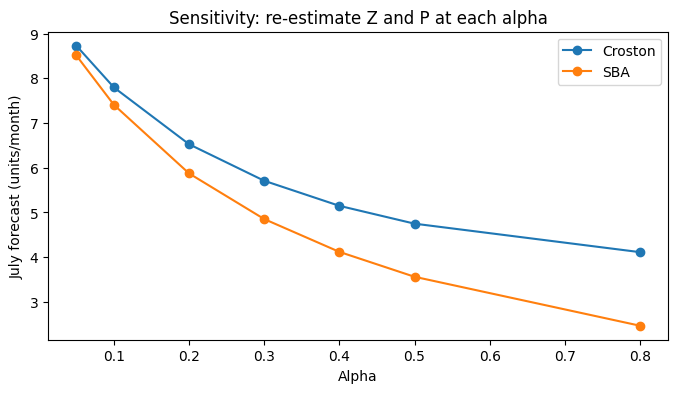

In [9]:
rows=[]
for a in [.05,.1,.2,.3,.4,.5,.8]:
    r=croston_sba(demand,a).iloc[-1]
    rows.append([a,r.Z,r.P,1-a/2,100*a/2,r.Croston_next,r.SBA_next])
sensitivity=pd.DataFrame(rows,columns=['alpha','Z','P','Factor','Reduction %','Croston','SBA'])
display(sensitivity.round(4))
fig,ax=plt.subplots(figsize=(8,4)); ax.plot(sensitivity.alpha,sensitivity.Croston,marker='o',label='Croston'); ax.plot(sensitivity.alpha,sensitivity.SBA,marker='o',label='SBA'); ax.set(xlabel='Alpha',ylabel='July forecast (units/month)',title='Sensitivity: re-estimate Z and P at each alpha'); ax.legend(); plt.show()

## 11. Process diagram

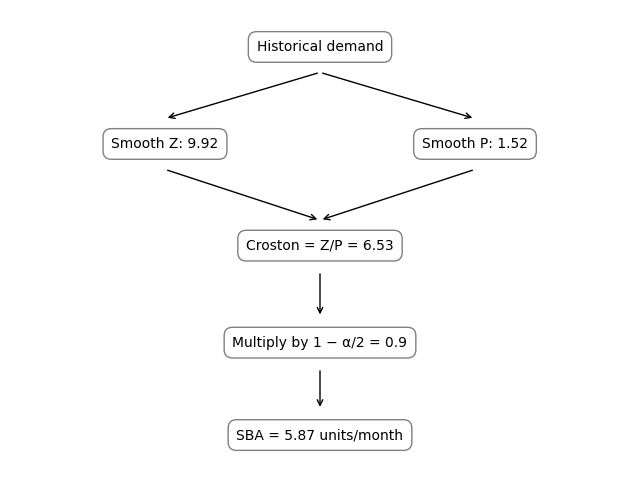

In [10]:
fig,ax=plt.subplots(figsize=(8,6)); ax.axis('off')
boxes=[(.5,.92,'Historical demand'),(.25,.71,'Smooth Z: 9.92'),(.75,.71,'Smooth P: 1.52'),(.5,.49,'Croston = Z/P = 6.53'),(.5,.28,'Multiply by 1 − α/2 = 0.9'),(.5,.08,'SBA = 5.87 units/month')]
for x,y,t in boxes: ax.text(x,y,t,ha='center',va='center',bbox=dict(boxstyle='round,pad=.6',facecolor='none',edgecolor='gray'),transform=ax.transAxes)
for a,b in [(0,1),(0,2),(1,3),(2,3),(3,4),(4,5)]:
    x,y,_=boxes[a]; xx,yy,_=boxes[b]; ax.annotate('',xy=(xx,yy+.055),xytext=(x,y-.055),xycoords='axes fraction',arrowprops=dict(arrowstyle='->'))
plt.show()

## 12. Practice questions with solutions
1. If Croston forecasts 20 units/month and alpha=0.3, what is SBA? **Solution:** $20(1-0.3/2)=17$.
2. If July has zero demand after our six-month example, what changes? **Solution:** elapsed time increases, but Z=9.92 and P=1.52 remain unchanged. SBA remains 5.8737.
3. If August then has demand 14, what is the new SBA? **Solution:** Q=2, Z=0.8(9.92)+0.2(14)=10.736, P=0.8(1.52)+0.2(2)=1.616. SBA=0.9(10.736/1.616), approximately 5.98 units/month.

In [11]:
practice=croston_sba(np.r_[demand,0,14],alpha)
display(practice.tail(2).round(4))
assert np.isclose(practice.SBA_next.iloc[-1],.9*10.736/1.616)
assert croston_sba([0,0,0]).SBA_next.isna().all()
print('Practice and edge-case checks passed.')

,Actual,Elapsed,Q,Z,P,Croston_next,SBA_next,Croston_for_period,SBA_for_period
6,0.0,1.0,NaN,9.920,1.520,6.5263,5.8737,6.5263,5.8737
7,14.0,2.0,2.0,10.736,1.616,6.6436,5.9792,6.5263,5.8737


Practice and edge-case checks passed.


## 13. Revision and limitations
| Feature | Croston | SBA |
|---|---|---|
| Z and P updates | Same | Same |
| Zero demand updates | Neither estimate changes | Neither estimate changes |
| Forecast | Z/P | (1 − alpha/2) × Z/P |
| Statistical bias correction | None | Approximate |
| Obsolescence handling | No | No |

SBA is not guaranteed to outperform Croston. Choose alpha and compare methods with rolling-origin backtesting; evaluate errors on correctly shifted forecasts, and inventory service/cost if relevant. Do not treat the initial forecast as a genuine out-of-sample prediction of January. All-zero histories require a separate business policy (the function leaves them uninitialized). The correction uses a common smoothing factor; this tutorial does not cover other variants.

**Further reading:** Syntetos, A. A. & Boylan, J. E. (2005). *The accuracy of intermittent demand estimates*. International Journal of Forecasting, 21(2), 303–314. Croston, J. D. (1972). *Forecasting and stock control for intermittent demands*. Operational Research Quarterly, 23(3), 289–303.

**Takeaway:** everything learned about Z, Q and P stays the same; SBA corrects the final forecast rate.